# **DSK807: Applied Machine Learning**
## L06 Hands-on: Logistic Regression & Text Classification

This notebook has two main examples:

1. **Binary classification with numerical features**
   - Logistic Regression
   - train/test split and stratification
   - feature scaling
   - coefficients before and after scaling
   - probabilities, predictions, confusion matrix, accuracy, precision, recall, and F1

2. **Multiclass text classification**
   - CountVectorizer
   - TF–IDF
   - Logistic Regression
   - multiclass evaluation
   - comparison of vectorization methods

### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

# **Part 1: Binary Classification with Numerical Data**

We will use the **Breast Cancer Wisconsin dataset** included with scikit-learn.

The complete dataset contains 30 numerical features. To keep the example easy to inspect, we deliberately select only **five features**.

The target has two classes:

- `0` = malignant (Cancer)
- `1` = benign (No Cancer)

![Examples from the dataset.](https://miro.medium.com/v2/1*pxFCmhRFTighUn88baLcSA.png)

In [2]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)

df = data.frame.copy()

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## **1.1 Select a small set of features**

In [3]:
features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean smoothness",
    "mean concavity"
]

X = df[features]
y = df["target"]

print("Features:")
display(X.head())

print("\nClass distribution:")
print(y.value_counts().rename(index={0: "malignant", 1: "benign"}))

Features:


,mean radius,mean texture,mean perimeter,mean smoothness,mean concavity
0,17.99,10.38,122.80,0.11840,0.3001
1,20.57,17.77,132.90,0.08474,0.0869
2,19.69,21.25,130.00,0.10960,0.1974
3,11.42,20.38,77.58,0.14250,0.2414
4,20.29,14.34,135.10,0.10030,0.1980



Class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


### Look at the feature scales

Before fitting the model, inspect the ranges of the five features.

**Question:** Are all features measured on comparable scales?

In [4]:
X.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.1100
mean texture,19.289649,4.301036,9.71000,39.2800
mean perimeter,91.969033,24.298981,43.79000,188.5000
mean smoothness,0.096360,0.014064,0.05263,0.1634
mean concavity,0.088799,0.079720,0.00000,0.4268


## **1.2 Train / test split**

We use `stratify=y` so that the class proportions are approximately preserved in both sets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y  
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training samples: 426
Test samples: 143

Training class proportions:
target
0    0.373239
1    0.626761
Name: proportion, dtype: float64

Test class proportions:
target
0    0.370629
1    0.629371
Name: proportion, dtype: float64


## **1.3 Logistic Regression without scaling**

First, fit Logistic Regression using the original feature values.

We increase `max_iter` because optimization **can** require more iterations when features are on very different scales.

In [6]:
lr_raw = LogisticRegression(max_iter=5000) # default max_iter=100

lr_raw.fit(X_train, y_train)

y_pred_raw = lr_raw.predict(X_test)
y_prob_raw = lr_raw.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_raw))
print("F1 (binary):", f1_score(y_test, y_pred_raw))

Accuracy: 0.9370629370629371
F1 (binary): 0.9497206703910615


### **Inspect predicted probabilities**

In [7]:
probability_example = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "P(malignant)": y_prob_raw[:10, 0],
    "P(benign)": y_prob_raw[:10, 1],
    "Predicted": y_pred_raw[:10]
})

probability_example.round(3)

,Actual,P(malignant),P(benign),Predicted
0,1,0.063,0.937,1
1,0,0.979,0.021,0
2,1,0.491,0.509,1
3,1,0.164,0.836,1
4,0,0.519,0.481,0
5,0,1.000,0.000,0
6,0,0.665,0.335,0
7,0,0.979,0.021,0
8,0,0.999,0.001,0
9,1,0.005,0.995,1


### **Confusion matrix**

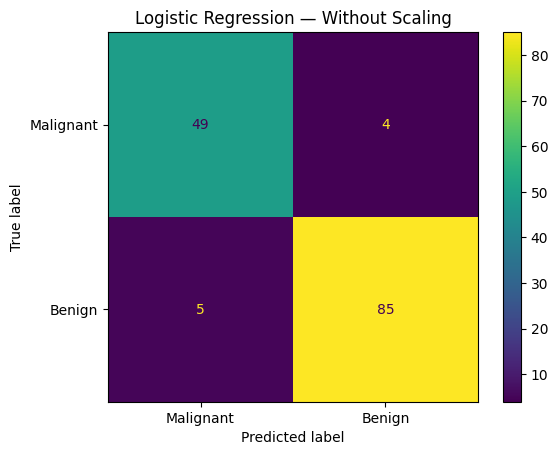

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_raw,
    display_labels=["Malignant", "Benign"]
)

plt.title("Logistic Regression — Without Scaling")
plt.show()

## **1.4 Scale the features**

`StandardScaler` transforms each feature approximately as:

$$
x' = \frac{x-\mu}{\sigma}
$$[link text]

After scaling, each training feature has approximately:

- mean = 0
- standard deviation = 1

**Important:** the scaler is fitted **only on the training data**.

In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_summary = pd.DataFrame(
    X_train_scaled,
    columns=features
).agg(["mean", "std"]).T

scaled_summary.round(3)

,mean,std
mean radius,-0.0,1.001
mean texture,0.0,1.001
mean perimeter,-0.0,1.001
mean smoothness,-0.0,1.001
mean concavity,-0.0,1.001


### MinMax Scaling

In [10]:
from sklearn.preprocessing import MinMaxScaler

mmscaler = MinMaxScaler()

X_train_mmscaled = mmscaler.fit_transform(X_train)
X_test_mmscaled = mmscaler.transform(X_test)

mmscaled_summary = pd.DataFrame(
    X_train_mmscaled,
    columns=features
).agg(["mean", "std"]).T

mmscaled_summary.round(3)

,mean,std
mean radius,0.336,0.166
mean texture,0.324,0.150
mean perimeter,0.330,0.167
mean smoothness,0.419,0.167
mean concavity,0.209,0.190


## **1.5 Logistic Regression after scaling**

In [11]:
## With Standarization (StandardScaler)
lr_scaled = LogisticRegression(max_iter=5000)

lr_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = lr_scaled.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("F1 (binary):", f1_score(y_test, y_pred_scaled))

Accuracy: 0.9020979020979021
F1 (binary): 0.9204545454545454


In [12]:
## With MinMax Scaling
lr_mmscaled = LogisticRegression(max_iter=5000)

lr_mmscaled.fit(X_train_mmscaled, y_train)

y_pred_mmscaled = lr_mmscaled.predict(X_test_mmscaled)

print("Accuracy:", accuracy_score(y_test, y_pred_mmscaled))
print("F1 (binary):", f1_score(y_test, y_pred_mmscaled))

Accuracy: 0.9440559440559441
F1 (binary): 0.956989247311828


## **1.6 What happened to the coefficients?**

Remember:

$$
z = \beta_0+\beta_1x_1+\cdots+\beta_px_p
$$

A coefficient represents the change in the linear score associated with a **one-unit change in its feature**, holding the other features fixed.

When we change the units of the features through scaling, the numerical values of the coefficients also change.

In [13]:
coef_comparison = pd.DataFrame({
    "Feature": features,
    "Coefficient (original scale)": lr_raw.coef_[0],
    "Coefficient (standardized)": lr_scaled.coef_[0],
    "Coefficient (MinMaxScaled)": lr_mmscaled.coef_[0]
})

coef_comparison.round(4)

,Feature,Coefficient (original scale),Coefficient (standardized),Coefficient (MinMaxScaled)
0,mean radius,2.8047,-2.0721,-4.2325
1,mean texture,-0.1996,-1.4019,-2.7895
2,mean perimeter,-0.5760,-1.8828,-4.2757
3,mean smoothness,-0.4526,-1.5583,-2.6779
4,mean concavity,-1.2372,-1.0757,-3.6944


### Visual comparison of the coefficients

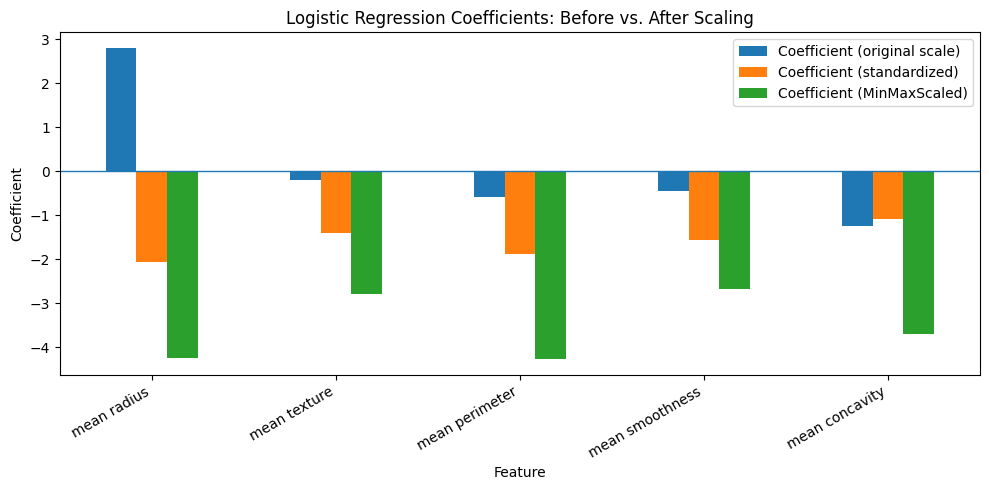

In [14]:
coef_plot = coef_comparison.set_index("Feature")

ax = coef_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.axhline(0, linewidth=1)
ax.set_ylabel("Coefficient")
ax.set_title("Logistic Regression Coefficients: Before vs. After Scaling")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## **1.7 Compare performance**

In [15]:
def binary_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

comparison = pd.DataFrame({
    "Without scaling": binary_metrics(y_test, y_pred_raw),
    "With Standard scaling": binary_metrics(y_test, y_pred_scaled),
    "With MinMax scaling": binary_metrics(y_test, y_pred_mmscaled)
}).T

comparison.round(3)

,Accuracy,Precision,Recall,F1
Without scaling,0.937,0.955,0.944,0.950
With Standard scaling,0.902,0.942,0.900,0.920
With MinMax scaling,0.944,0.927,0.989,0.957


### Classification report

In [16]:
print(classification_report(
    y_test,
    y_pred_mmscaled,
    target_names=["Malignant", "Benign"]
))

              precision    recall  f1-score   support

   Malignant       0.98      0.87      0.92        53
      Benign       0.93      0.99      0.96        90

    accuracy                           0.94       143
   macro avg       0.95      0.93      0.94       143
weighted avg       0.95      0.94      0.94       143



## **1.8 The recommended workflow: use a Pipeline**

A pipeline ensures that the scaler is fitted on the training data and that exactly the same transformation is applied to new data.

In [17]:
numeric_model = Pipeline([
    ("scaler", MinMaxScaler()),
    ("logistic_regression", LogisticRegression(max_iter=5000))
])

numeric_model.fit(X_train, y_train)

y_pred_pipeline = numeric_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_pipeline,
    target_names=["Malignant", "Benign"]
))

              precision    recall  f1-score   support

   Malignant       0.98      0.87      0.92        53
      Benign       0.93      0.99      0.96        90

    accuracy                           0.94       143
   macro avg       0.95      0.93      0.94       143
weighted avg       0.95      0.94      0.94       143



---
# **Part 1B: Logistic Regression vs. Support Vector Machine**

We now use the **same train/test split** to compare Logistic Regression with an SVM.

For SVM, feature scaling is especially important because the classifier depends on distances between observations.


In [18]:
# Logistic Regression with StandardScaler
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

# SVM with an RBF kernel
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

lr_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
svm_pred = svm_model.predict(X_test)

lr_svm_results = pd.DataFrame({
    "Logistic Regression": binary_metrics(y_test, lr_pred),
    "SVM (RBF)": binary_metrics(y_test, svm_pred)
}).T

lr_svm_results.round(3)


,Accuracy,Precision,Recall,F1
Logistic Regression,0.902,0.942,0.900,0.920
SVM (RBF),0.944,0.966,0.944,0.955


## **1.9 Tune the SVM with Grid Search**

Instead of choosing `C`, `kernel`, and `gamma` manually, `GridSearchCV` evaluates several combinations using cross-validation.

`cv=5` means that each parameter combination is evaluated using **5-fold cross-validation on the training data**.

The test set remains untouched until the best configuration has been selected.


In [19]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC())
])

# Separate parameter grids avoid testing gamma when using a linear kernel.
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.01, 0.1, 1]
    }
]

grid_svm = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=2,
    scoring="accuracy",
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print("Best parameters:")
print(grid_svm.best_params_)
print("\nBest mean CV accuracy:", round(grid_svm.best_score_, 3))


Best parameters:
{'classifier__C': 1, 'classifier__gamma': 0.1, 'classifier__kernel': 'rbf'}

Best mean CV accuracy: 0.955


### **Compare Logistic Regression, default SVM, and tuned SVM**

`GridSearchCV` automatically refits a final model on the **entire training set** using the best hyperparameters (`refit=True` by default).


In [20]:
best_svm = grid_svm.best_estimator_
best_svm_pred = best_svm.predict(X_test)

numeric_final_results = pd.DataFrame({
    "Logistic Regression": binary_metrics(y_test, lr_pred),
    "SVM (RBF, default)": binary_metrics(y_test, svm_pred),
    "SVM (Grid Search)": binary_metrics(y_test, best_svm_pred)
}).T

numeric_final_results.round(3)


,Accuracy,Precision,Recall,F1
Logistic Regression,0.902,0.942,0.900,0.920
"SVM (RBF, default)",0.944,0.966,0.944,0.955
SVM (Grid Search),0.951,0.966,0.956,0.961


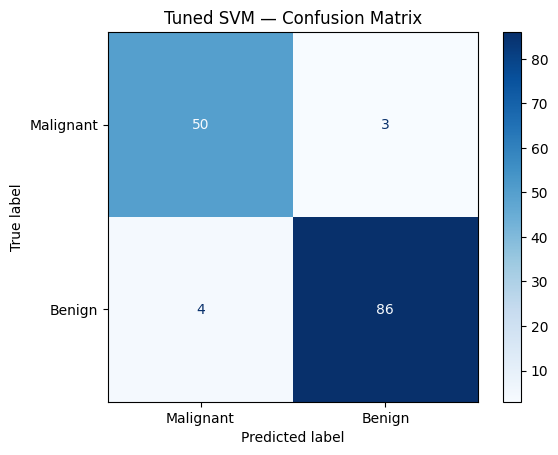

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_svm_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Blues"
)

plt.title("Tuned SVM — Confusion Matrix")
plt.show()


---
# **Part 2: Multiclass Text Classification**

Now our input is **text**, but Logistic Regression requires numerical features.

We therefore need:

$$
\text{Text}
\rightarrow
\text{Vectorization}
\rightarrow
\text{Logistic Regression}
\rightarrow
\text{Class}
$$

We will use a subset of the **20 Newsgroups** dataset with four topics:

- `comp.graphics`
- `rec.sport.baseball`
- `sci.space`
- `talk.politics.misc`

This gives us a genuine **multiclass classification** problem.

In [22]:
from sklearn.datasets import fetch_20newsgroups

categories = [
    "comp.graphics",
    "rec.sport.baseball",
    "sci.space",
    "talk.politics.misc"
]

train_text = fetch_20newsgroups(
    subset="train",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    random_state=RANDOM_STATE
)

test_text = fetch_20newsgroups(
    subset="test",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    random_state=RANDOM_STATE
)

print("Training documents:", len(train_text.data))
print("Test documents:", len(test_text.data))
print("Classes:", train_text.target_names)

Training documents: 2239
Test documents: 1490
Classes: ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.misc']


## **2.1 Inspect the raw text**

In [23]:
example_id = 20

print("CLASS:")
print(train_text.target_names[train_text.target[example_id]])

print("\nTEXT:")
print(train_text.data[example_id][:1200])

CLASS:
sci.space

TEXT:
Re: Space billboards

Even easier to implement than writing messages on the Moon, once upon
a time a group of space activists I belonged to in Seattle considered
a "Goodyear Blimp in orbit".  The idea was to use a large structure
that could carry an array of lights like the Goodyear Blimp has.
Placed in a low Earth orbit of high inclination, it could eventually
be seen by almost everyone on Earth.  Only our collective disapproval
of cluttering up space with such a thing stopped us from pursuing
it.  It had quite feasible economics, which I will not post here
because I don't want to encourage the idea (if you want to do such
a thing, go figure it out for yourself).

Dani Eder



# **Example 2A — CountVectorizer**

`CountVectorizer` creates a **document-term matrix**.

Each column represents a vocabulary term and each cell contains the number of times that term occurs in a document.

For example:

| Document | space | baseball | image |
|---|---:|---:|---:|
| Document A | 3 | 0 | 1 |
| Document B | 0 | 4 | 0 |

Let's first use a tiny example so we can actually see the vectors.

In [24]:
from sklearn.feature_extraction.text import CountVectorizer

tiny_documents = [
    "space mission to mars",
    "mars mission launches spacecraft",
    "baseball team wins game"
]

tiny_count = CountVectorizer()
tiny_matrix = tiny_count.fit_transform(tiny_documents)

tiny_df = pd.DataFrame(
    tiny_matrix.toarray(),
    columns=tiny_count.get_feature_names_out()
)

tiny_df

,baseball,game,launches,mars,mission,space,spacecraft,team,to,wins
0,0,0,0,1,1,1,0,0,1,0
1,0,0,1,1,1,0,1,0,0,0
2,1,1,0,0,0,0,0,1,0,1


## 2.2 CountVectorizer + Logistic Regression

For the real dataset, we keep the representation sparse. We do **not** convert the full matrix to a dense array.

In [25]:
count_model = Pipeline([
    ("vectorizer", CountVectorizer(
        stop_words="english",
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=2000
    ))
])

count_model.fit(train_text.data, train_text.target)

count_pred = count_model.predict(test_text.data)

print(classification_report(
    test_text.target,
    count_pred,
    target_names=test_text.target_names
))

                    precision    recall  f1-score   support

     comp.graphics       0.89      0.87      0.88       389
rec.sport.baseball       0.77      0.91      0.83       397
         sci.space       0.81      0.76      0.79       394
talk.politics.misc       0.82      0.72      0.77       310

          accuracy                           0.82      1490
         macro avg       0.82      0.81      0.82      1490
      weighted avg       0.82      0.82      0.82      1490



### Confusion matrix: CountVectorizer

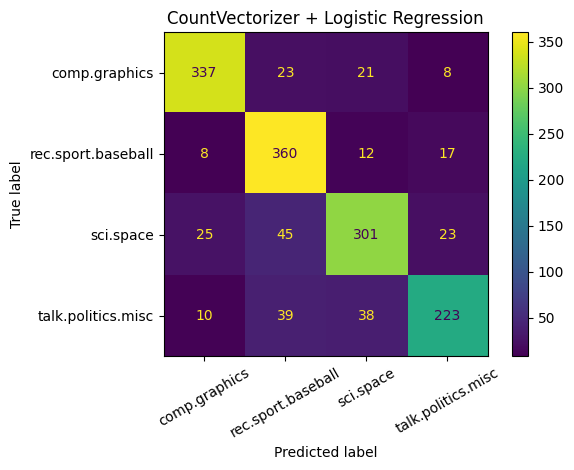

In [26]:
ConfusionMatrixDisplay.from_predictions(
    test_text.target,
    count_pred,
    display_labels=test_text.target_names,
    xticks_rotation=30
)

plt.title("CountVectorizer + Logistic Regression")
plt.tight_layout()
plt.show()

## 2.3 Inspect the vocabulary and matrix shape

In [27]:
count_vectorizer = count_model.named_steps["vectorizer"]

X_train_count = count_vectorizer.transform(train_text.data)

print("Document-term matrix shape:", X_train_count.shape)
print("Vocabulary size:", len(count_vectorizer.vocabulary_))
print("Matrix type:", type(X_train_count))

Document-term matrix shape: (2239, 12774)
Vocabulary size: 12774
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


# **Example 2B: TF–IDF**

Raw counts give frequent words large values.

TF–IDF gives more weight to terms that are important in a particular document but less common across the collection.

A common formulation is:

$$
\text{TF-IDF}(t,d)
=
\text{TF}(t,d)\times\text{IDF}(t)
$$

with

$$
\text{IDF}(t)
\approx
\log\left(\frac{N}{df(t)}\right)
$$

The exact implementation can include smoothing and normalization.

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

tiny_tfidf = TfidfVectorizer() # try ngram_range = (1,2)
tiny_tfidf_matrix = tiny_tfidf.fit_transform(tiny_documents)

tiny_tfidf_df = pd.DataFrame(
    tiny_tfidf_matrix.toarray(),
    columns=tiny_tfidf.get_feature_names_out()
)

tiny_tfidf_df.round(3)

,baseball,game,launches,mars,mission,space,spacecraft,team,to,wins
0,0.0,0.0,0.000,0.428,0.428,0.563,0.000,0.0,0.563,0.0
1,0.0,0.0,0.563,0.428,0.428,0.000,0.563,0.0,0.000,0.0
2,0.5,0.5,0.000,0.000,0.000,0.000,0.000,0.5,0.000,0.5


## 2.4 TF–IDF + Logistic Regression

In [29]:
tfidf_model = Pipeline([
    ("vectorizer", TfidfVectorizer(
        stop_words="english",  # try ngram_range = (1,2)
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=2000
    ))
])

tfidf_model.fit(train_text.data, train_text.target)

tfidf_pred = tfidf_model.predict(test_text.data)

print(classification_report(
    test_text.target,
    tfidf_pred,
    target_names=test_text.target_names
))

                    precision    recall  f1-score   support

     comp.graphics       0.92      0.90      0.91       389
rec.sport.baseball       0.83      0.92      0.88       397
         sci.space       0.84      0.83      0.83       394
talk.politics.misc       0.89      0.80      0.84       310

          accuracy                           0.87      1490
         macro avg       0.87      0.86      0.86      1490
      weighted avg       0.87      0.87      0.86      1490



## **2.5 TF–IDF + Support Vector Machine**

Now we keep the **same TF–IDF representation** and change only the classifier.

This makes the comparison with Logistic Regression fair: both models receive the same training and test documents and the same type of features.


In [ ]:
tfidf_svm = Pipeline([
    ("vectorizer", TfidfVectorizer(
        stop_words="english",
        min_df=2
    )),
    ("classifier", SVC(
        kernel="rbf", # 這邊的都可以調整
        C=1.0
    ))
])

tfidf_svm.fit(train_text.data, train_text.target)
tfidf_svm_pred = tfidf_svm.predict(test_text.data)

print(classification_report(
    test_text.target,
    tfidf_svm_pred,
    target_names=test_text.target_names
))


                    precision    recall  f1-score   support

     comp.graphics       0.91      0.88      0.90       389
rec.sport.baseball       0.85      0.91      0.88       397
         sci.space       0.79      0.85      0.81       394
talk.politics.misc       0.90      0.77      0.83       310

          accuracy                           0.86      1490
         macro avg       0.86      0.85      0.85      1490
      weighted avg       0.86      0.86      0.86      1490



In [47]:
def multiclass_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted"),
        "Micro F1": f1_score(y_true, y_pred, average="micro")
    }

### **Logistic Regression vs. SVM on TF–IDF**


In [48]:
tfidf_lr_vs_svm = pd.DataFrame({
    "Logistic Regression": multiclass_metrics(test_text.target, tfidf_pred),
    "SVM (Linear)": multiclass_metrics(test_text.target, tfidf_svm_pred)
}).T

tfidf_lr_vs_svm.round(3)


,Accuracy,Macro F1,Weighted F1,Micro F1
Logistic Regression,0.865,0.863,0.865,0.865
SVM (Linear),0.856,0.855,0.856,0.856


## **2.6 Grid Search for the Text SVM**

For high-dimensional sparse text features, a **linear SVM is often a strong baseline**.  
We therefore tune `C` first, while keeping the kernel linear.

Again, cross-validation uses only the **training set**.


In [49]:
text_svm_grid = Pipeline([
    ("vectorizer", TfidfVectorizer(
        stop_words="english",
        min_df=2
    )),
    ("classifier", SVC(kernel="linear"))
])

text_param_grid = {
    "classifier__C": [0.1, 1, 10]
}

grid_text_svm = GridSearchCV(
    text_svm_grid,
    text_param_grid,
    cv=2,
    scoring="accuracy",
    n_jobs=-1
)

grid_text_svm.fit(train_text.data, train_text.target)

print("Best parameters:")
print(grid_text_svm.best_params_)
print("\nBest mean CV accuracy:", round(grid_text_svm.best_score_, 3))


Best parameters:
{'classifier__C': 1}

Best mean CV accuracy: 0.877


In [50]:
best_text_svm = grid_text_svm.best_estimator_
best_text_svm_pred = best_text_svm.predict(test_text.data)

text_model_comparison = pd.DataFrame({
    "TF-IDF + Logistic Regression": multiclass_metrics(test_text.target, tfidf_pred),
    "TF-IDF + SVM (Linear)": multiclass_metrics(test_text.target, tfidf_svm_pred),
    "TF-IDF + SVM (Grid Search)": multiclass_metrics(test_text.target, best_text_svm_pred)
}).T

text_model_comparison.round(3)


,Accuracy,Macro F1,Weighted F1,Micro F1
TF-IDF + Logistic Regression,0.865,0.863,0.865,0.865
TF-IDF + SVM (Linear),0.856,0.855,0.856,0.856
TF-IDF + SVM (Grid Search),0.852,0.850,0.851,0.852


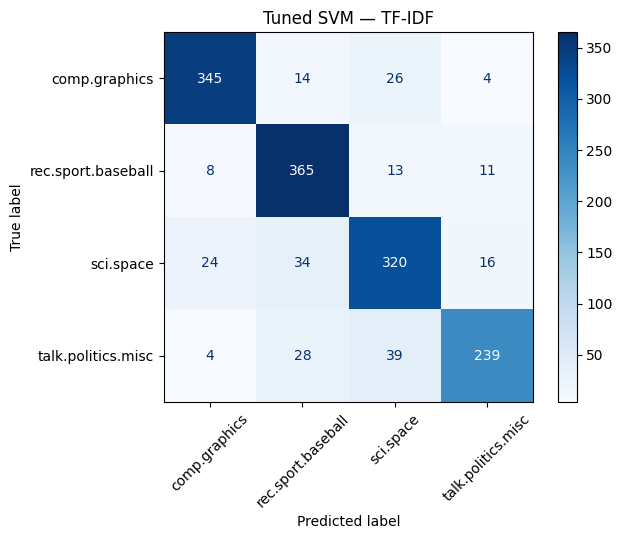

In [35]:
ConfusionMatrixDisplay.from_predictions(
    test_text.target,
    best_text_svm_pred,
    display_labels=test_text.target_names,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Tuned SVM — TF-IDF")
plt.show()


### Confusion matrix: TF–IDF

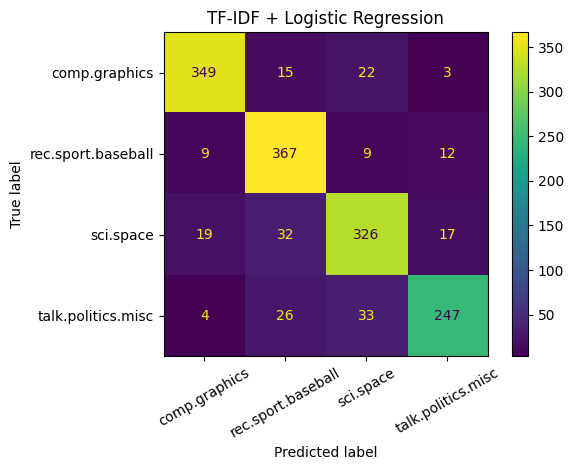

In [36]:
ConfusionMatrixDisplay.from_predictions(
    test_text.target,
    tfidf_pred,
    display_labels=test_text.target_names,
    xticks_rotation=30
)

plt.title("TF-IDF + Logistic Regression")
plt.tight_layout()
plt.show()

# 2.5 CountVectorizer vs. TF–IDF

In [37]:
def multiclass_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted"),
        "Micro F1": f1_score(y_true, y_pred, average="micro")
    }

text_results = pd.DataFrame({
    "CountVectorizer": multiclass_metrics(test_text.target, count_pred),
    "TF-IDF": multiclass_metrics(test_text.target, tfidf_pred)
}).T

text_results.round(3)

,Accuracy,Macro F1,Weighted F1,Micro F1
CountVectorizer,0.819,0.816,0.818,0.819
TF-IDF,0.865,0.863,0.865,0.865


## 2.6 What words does Logistic Regression associate with each class?

With CountVectorizer or TF–IDF, each input feature corresponds to a vocabulary term.

That makes the learned Logistic Regression coefficients particularly interesting to inspect.

In [38]:
vectorizer = tfidf_model.named_steps["vectorizer"]
classifier = tfidf_model.named_steps["classifier"]

feature_names = np.array(vectorizer.get_feature_names_out())

for class_id, class_name in enumerate(train_text.target_names):
    top_indices = np.argsort(classifier.coef_[class_id])[-10:][::-1]
    top_terms = feature_names[top_indices]

    print(f"\n{class_name}")
    print(", ".join(top_terms))


comp.graphics
graphics, image, file, files, 3d, computer, hi, windows, card, format

rec.sport.baseball
baseball, game, team, year, games, players, jewish, runs, hit, cubs

sci.space
space, nasa, orbit, moon, launch, spacecraft, earth, shuttle, lunar, solar

talk.politics.misc
people, clinton, government, tax, president, state, drugs, men, evidence, trial


## 2.7 Predict new text

In [51]:
new_documents = [
    "The spacecraft entered orbit and began transmitting data.",
    "The pitcher had an excellent game and the team scored in the final inning.",
    "The image rendering software supports three dimensional graphics."
]

predictions = tfidf_model.predict(new_documents)
probabilities = tfidf_model.predict_proba(new_documents)

for text, pred, probs in zip(new_documents, predictions, probabilities):
    print("\nTEXT:", text)
    print("PREDICTION:", train_text.target_names[pred])

    result = pd.Series(
        probs,
        index=train_text.target_names
    ).sort_values(ascending=False)

    display(result.round(3).to_frame("Probability"))


TEXT: The spacecraft entered orbit and began transmitting data.
PREDICTION: sci.space


,Probability
sci.space,0.711
rec.sport.baseball,0.116
comp.graphics,0.093
talk.politics.misc,0.081



TEXT: The pitcher had an excellent game and the team scored in the final inning.
PREDICTION: rec.sport.baseball


,Probability
rec.sport.baseball,0.877
sci.space,0.047
comp.graphics,0.044
talk.politics.misc,0.032



TEXT: The image rendering software supports three dimensional graphics.
PREDICTION: comp.graphics


,Probability
comp.graphics,0.887
sci.space,0.047
rec.sport.baseball,0.036
talk.politics.misc,0.029


---
# Optional Extension — Sentence Embeddings

**Skip this section if time is limited.**

CountVectorizer and TF–IDF represent documents using vocabulary-based sparse vectors.

A sentence embedding represents an entire text as a **dense numerical vector**:

$$
\text{Text}
\rightarrow
\text{Sentence Transformer}
\rightarrow
\text{Dense Vector}
\rightarrow
\text{Logistic Regression}
$$

Unlike bag-of-words representations, pretrained sentence embeddings can encode semantic information and similarities between texts.

The first cell installs `sentence-transformers` in Colab.

In [40]:
# Run only if you want to present the optional embedding example.
!pip -q install sentence-transformers

In [41]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Encoding the full dataset can take some time.
X_train_embeddings = embedding_model.encode(
    train_text.data,
    batch_size=64,
    show_progress_bar=True
)

X_test_embeddings = embedding_model.encode(
    test_text.data,
    batch_size=64,
    show_progress_bar=True
)

print("Training embedding shape:", X_train_embeddings.shape)
print("Test embedding shape:", X_test_embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/35 [00:00<?, ?it/s]

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

Training embedding shape: (2239, 384)
Test embedding shape: (1490, 384)


## Logistic Regression on sentence embeddings

In [52]:
embedding_classifier = LogisticRegression(max_iter=2000)

embedding_classifier.fit(
    X_train_embeddings,
    train_text.target
)

embedding_pred = embedding_classifier.predict(
    X_test_embeddings
)

print(classification_report(
    test_text.target,
    embedding_pred,
    target_names=test_text.target_names
))

                    precision    recall  f1-score   support

     comp.graphics       0.93      0.92      0.92       389
rec.sport.baseball       0.89      0.93      0.91       397
         sci.space       0.85      0.83      0.84       394
talk.politics.misc       0.86      0.85      0.86       310

          accuracy                           0.88      1490
         macro avg       0.88      0.88      0.88      1490
      weighted avg       0.88      0.88      0.88      1490



## Compare all representations

In [53]:
all_results = pd.DataFrame({
    "CountVectorizer": multiclass_metrics(test_text.target, count_pred),
    "TF-IDF": multiclass_metrics(test_text.target, tfidf_pred),
    "Sentence Transformer": multiclass_metrics(test_text.target, embedding_pred)
}).T

all_results.round(3)

,Accuracy,Macro F1,Weighted F1,Micro F1
CountVectorizer,0.819,0.816,0.818,0.819
TF-IDF,0.865,0.863,0.865,0.865
Sentence Transformer,0.884,0.882,0.884,0.884
